In [ ]:
# 20_03

In [ ]:
# 차분(변화량) 구하기 : .diff()

In [1]:
PATH='C:\\ex\\data\\20_cmapss_fd001_sample.csv'

import pandas as pd
df=pd.read_csv(PATH)

In [11]:
pd.set_option('display.precision', 2)

In [12]:
df['s_4'].diff()

0        NaN
1       0.12
2      -4.31
3       9.13
4      -3.77
        ... 
1111   -1.86
1112   -0.11
1113   -6.74
1114    4.13
1115   -2.28
Name: s_4, Length: 1116, dtype: float64

In [13]:
df['s_4'].diff().abs().max()

np.float64(18.200000000000045)

In [14]:
PATH='C:\\ex\\data\\20_cmapss_fd001_sample.csv' # 기존 데이터

import pandas as pd
df=pd.read_csv(PATH)

In [ ]:
# 실습 1

In [33]:
# 2번 엔진 골라 작동 회차 순으로 정렬
e2=df[df['unit_nr']==2].sort_values('time_cycles')

In [21]:
e2.describe()

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
count,287.0,287.00,2.87e+02,2.87e+02,287.0,287.00,287.00,287.00,287.00,287.00,...,287.00,287.00,287.00,287.00,287.00,287.00,287.0,287.0,287.00,287.00
mean,2.0,144.00,-1.79e-04,-6.62e-06,100.0,518.67,641.75,1591.27,1408.95,14.62,...,517.43,2388.10,8138.26,8.52,0.03,393.97,2388.0,100.0,38.45,23.05
std,0.0,82.99,2.07e-03,3.06e-04,0.0,0.00,0.49,4.90,6.54,0.00,...,2.15,0.08,11.93,0.08,0.00,1.47,0.0,0.0,0.27,0.15
min,2.0,1.00,-6.40e-03,-8.00e-04,100.0,518.67,640.46,1576.71,1391.53,14.62,...,512.86,2387.90,8099.12,8.33,0.03,391.00,2388.0,100.0,37.88,22.70
25%,2.0,72.50,-1.60e-03,-2.00e-04,100.0,518.67,641.39,1588.05,1404.36,14.62,...,515.65,2388.04,8130.82,8.46,0.03,393.00,2388.0,100.0,38.23,22.92
50%,2.0,144.00,-2.00e-04,0.00e+00,100.0,518.67,641.70,1591.41,1408.96,14.62,...,517.23,2388.09,8138.29,8.52,0.03,394.00,2388.0,100.0,38.45,23.05
75%,2.0,215.50,1.30e-03,2.00e-04,100.0,518.67,642.14,1594.74,1413.64,14.62,...,519.15,2388.15,8145.94,8.59,0.03,395.00,2388.0,100.0,38.66,23.18
max,2.0,287.00,5.00e-03,9.00e-04,100.0,518.67,642.87,1604.85,1423.70,14.62,...,521.96,2388.30,8176.36,8.70,0.03,398.00,2388.0,100.0,39.06,23.39


In [42]:
# 창 크기 5로 s_4의 이동평균(rolling)을 구해 새 열(m5)로 담기
e2['m5_4']=e2['s_4'].rolling(window=5).mean()

In [32]:
e2.isna().sum() # m5_4 열에 결측치 4개 존재
# 4개는 이동평균을 구함에 따라 생긴 것으로, 창을 못 채운 구간과 일치함

unit_nr        0
time_cycles    0
setting_1      0
setting_2      0
setting_3      0
s_1            0
s_2            0
s_3            0
s_4            0
s_5            0
s_6            0
s_7            0
s_8            0
s_9            0
s_10           0
s_11           0
s_12           0
s_13           0
s_14           0
s_15           0
s_16           0
s_17           0
s_18           0
s_19           0
s_20           0
s_21           0
m5_4           4
dtype: int64

In [ ]:
# 실습 2

In [43]:
# 창 크기 5로 s_4의 이동표준편차 구하고 새 열로 저장하기
e2['s5_4']=e2['s_4'].rolling(window=5).std()

In [44]:
# 다섯 번째 지점의 변동성 값(std)을 확인
e2['s5_4'].iloc[4].round(3) # 5.603

np.float64(5.603)

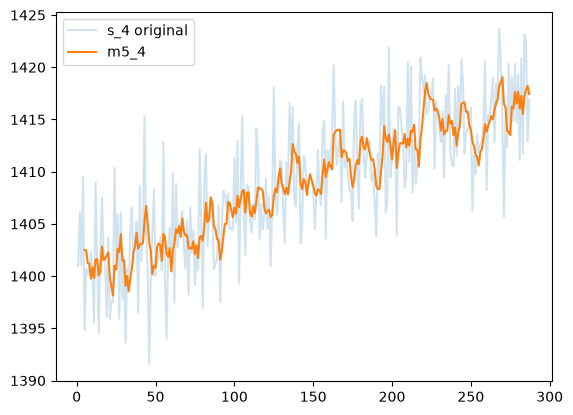

In [50]:
# 원본을 옅게, 이동평균을 진하게 겹쳐 그리기
import matplotlib.pyplot as plt

plt.plot(e2['time_cycles'], e2['s_4'], alpha=0.2, label='s_4 original')
plt.plot(e2['time_cycles'], e2['m5_4'], alpha=1, label='m5_4')
plt.legend()

plt.show()

In [ ]:
# 실습 3

In [51]:
# 직전 값과의 차이로 변화량을 구해서 새로운 컬럼으로 저장
e2['diff']=e2['s_4'].diff()

In [54]:
e2

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_15,s_16,s_17,s_18,s_19,s_20,s_21,s5_4,m5_4,diff
192,2,1,1.30e-03,6.00e-04,100.0,518.67,640.79,1583.91,1400.99,14.62,...,8.40,0.03,392,2388,100.0,38.94,23.26,NaN,NaN,NaN
193,2,2,1.00e-04,-6.00e-04,100.0,518.67,641.23,1580.40,1406.14,14.62,...,8.37,0.03,391,2388,100.0,39.03,23.25,NaN,NaN,5.15
194,2,3,-2.30e-03,3.00e-04,100.0,518.67,641.10,1582.31,1401.05,14.62,...,8.42,0.03,394,2388,100.0,38.81,23.28,NaN,NaN,-5.09
195,2,4,8.00e-04,-0.00e+00,100.0,518.67,640.78,1588.53,1409.53,14.62,...,8.37,0.03,393,2388,100.0,38.96,23.22,NaN,NaN,8.48
196,2,5,3.20e-03,2.00e-04,100.0,518.67,641.38,1581.18,1394.85,14.62,...,8.45,0.03,392,2388,100.0,39.01,23.33,5.60,1402.51,-14.68
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
474,2,283,4.00e-04,-3.00e-04,100.0,518.67,642.51,1597.28,1411.74,14.62,...,8.67,0.03,395,2388,100.0,37.95,22.70,4.38,1415.53,-9.10
475,2,284,3.00e-04,-0.00e+00,100.0,518.67,642.77,1597.95,1423.15,14.62,...,8.66,0.03,396,2388,100.0,37.93,22.85,5.47,1417.23,11.41
476,2,285,-2.00e-04,-1.00e-04,100.0,518.67,642.50,1604.83,1422.49,14.62,...,8.59,0.03,396,2388,100.0,38.07,22.86,5.94,1417.87,-0.66
477,2,286,8.00e-04,-3.00e-04,100.0,518.67,642.01,1591.69,1412.86,14.62,...,8.66,0.03,396,2388,100.0,37.98,22.85,5.48,1418.22,-9.63


In [70]:
# 변화량 절대값이 가장 큰 급변 회차(위치)를 찾기
print(round(e2['diff'].abs().max(),2))
print(e2['diff'].abs().idxmax())


14.68
196


In [ ]:
# 변화율 평균
round(e2['s_4'].pct_change().mean() * 100, 4) # 변화율 평균 : 0.49%

np.float64(0.0049)

In [ ]:
# 실습 4

In [73]:
df.columns

Index(['unit_nr', 'time_cycles', 'setting_1', 'setting_2', 'setting_3', 's_1',
       's_2', 's_3', 's_4', 's_5', 's_6', 's_7', 's_8', 's_9', 's_10', 's_11',
       's_12', 's_13', 's_14', 's_15', 's_16', 's_17', 's_18', 's_19', 's_20',
       's_21'],
      dtype='str')

In [ ]:
# 값이 변하는 센서만 목록으로 추리기

df1=df.iloc[:,5:]
cols=df1.columns.to_list()
variable_std=[]

for i in cols:
    if df1[i].std() > 0.01:
        variable_std.append(i)
        
print(variable_std) # 조건을 만족하는 총 14개의 센서(2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21번 센서)

['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']


In [ ]:
# 센서끼리 상관계수 계산하여 corr에 할당
corr=df[variable_std].corr()

In [ ]:
# 상관행렬 확인
corr

,s_2,s_3,s_4,s_7,s_8,s_9,s_11,s_12,s_13,s_14,s_15,s_17,s_20,s_21
s_2,1.00,0.66,0.69,-0.85,0.74,0.55,0.80,-0.84,0.67,0.30,0.81,0.70,-0.84,-0.83
s_3,0.66,1.00,0.62,-0.74,0.65,0.47,0.69,-0.75,0.57,0.26,0.71,0.62,-0.72,-0.73
s_4,0.69,0.62,1.00,-0.77,0.67,0.48,0.71,-0.76,0.60,0.25,0.73,0.64,-0.76,-0.75
s_7,-0.85,-0.74,-0.77,1.00,-0.83,-0.60,-0.89,0.94,-0.73,-0.32,-0.89,-0.78,0.92,0.91
s_8,0.74,0.65,0.67,-0.83,1.00,0.52,0.77,-0.82,0.63,0.29,0.78,0.68,-0.81,-0.80
s_9,0.55,0.47,0.48,-0.60,0.52,1.00,0.57,-0.60,0.47,0.19,0.59,0.49,-0.59,-0.60
s_11,0.80,0.69,0.71,-0.89,0.77,0.57,1.00,-0.89,0.68,0.29,0.85,0.73,-0.87,-0.86
s_12,-0.84,-0.75,-0.76,0.94,-0.82,-0.60,-0.89,1.00,-0.72,-0.33,-0.90,-0.78,0.93,0.91
s_13,0.67,0.57,0.60,-0.73,0.63,0.47,0.68,-0.72,1.00,0.24,0.69,0.61,-0.72,-0.71
s_14,0.30,0.26,0.25,-0.32,0.29,0.19,0.29,-0.33,0.24,1.00,0.29,0.26,-0.31,-0.30


In [ ]:
# s_11 기준, 양의 상관(같은 방향)을 절대값이 큰 순서로 상위 세 개 확인
print(corr['s_11'].drop('s_11').sort_values(ascending=False).head(3).round(3))

s_15    0.85
s_2     0.80
s_8     0.77
Name: s_11, dtype: float64


In [ ]:
# s_11 기준, 음의 상관(반대 방향)을 절대값이 큰 순서로 상위 세 개 확인
print(corr['s_11'].sort_values().head(3).round(3))

s_7    -0.89
s_12   -0.89
s_20   -0.87
Name: s_11, dtype: float64


In [ ]:
# 실습 5